1. Dowload https://archive.ics.uci.edu/dataset/438/health+news+in+twitter
2. Combine the files into one file
3. Extract the last column of the file (the tweets) and put them into a list of texts and call it **tweets**
4. Convert the **tweets** to a **TfIdf vectore** using **TfidfVectorizer**
5. Lower the dimensions of tweets to 500 with **PCA**
6. Cluster the **tweets** into K clusters; try these Ks: 50, 100, 200, 300, 400. Which K gives the best **silhouette_score**
7. For the best K, sample 5 tweets from each cluster and print them.
8. For the best K, print our the tweet closest to the centroid of the cluster (**cluster_centers_** has all the centroids). Use **cosine_distances** for measuring how close a tweet is to its centroid. 

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_distances
from sklearn.decomposition import PCA

In [2]:
data_dir = Path("Health-Tweets")
all_data = []

for file in data_dir.glob("*.txt"):
    rows = []

    with open(file, "r", encoding="latin-1") as f:
        for line in f:
            line = line.rstrip("\n")

            # Split into exactly 3 parts:
            # tweet_id | date | tweet
            parts = line.split("|", 2)

            if len(parts) == 3:
                rows.append(parts)

    df = pd.DataFrame(rows, columns=["tweet_id", "date", "tweet"])
    all_data.append(df)

combined_df = pd.concat(all_data, ignore_index=True)

In [3]:
tweets = combined_df["tweet"].tolist()

In [4]:
vectorizer = TfidfVectorizer(stop_words="english", min_df=2)
X_tfidf = vectorizer.fit_transform(tweets)
print("TF-IDF shape:", X_tfidf.shape)

TF-IDF shape: (63326, 20260)


In [5]:
pca = PCA(n_components=500, random_state=42)
X_pca = pca.fit_transform(X_tfidf)
print("PCA shape:", X_pca.shape)

PCA shape: (63326, 500)


In [ ]:
Ks = [50, 100, 200, 300, 400]
results = []
models = {}

for k in Ks:
    print(f"Training K-Means with K={k}...")

    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

    labels = kmeans.fit_predict(X_pca)

    score = silhouette_score(X_pca, labels)

    results.append({"K": k, "silhouette_score": score})
    
    models[k] = kmeans

    print(f"Silhouette score: {score:.4f}")

results_df = pd.DataFrame(results)
print(results_df)

best_k = int(results_df.loc[results_df["silhouette_score"].idxmax(), "K"])
print("Best K:", best_k)

Training K-Means with K=50...
Silhouette score: 0.0510
Training K-Means with K=100...
Silhouette score: 0.0458
Training K-Means with K=200...
Silhouette score: 0.0442
Training K-Means with K=300...
Silhouette score: 0.0382
Training K-Means with K=400...
Silhouette score: 0.0286


In [16]:
best_kmeans = models[best_k]
best_labels = best_kmeans.labels_

rng = np.random.default_rng(42)

for cluster_id in range(best_k):
    cluster_indices = np.where(best_labels == cluster_id)[0]

    sample_size = min(5, len(cluster_indices))

    sampled_indices = rng.choice(cluster_indices, size=sample_size, replace=False)

    print(f"\nCLUSTER {cluster_id} | {len(cluster_indices)} tweets")

    for idx in sampled_indices:
        print("-", tweets[idx])


CLUSTER 0 | 199 tweets
- Africa's medicine men key to halting Ebola spread in Guinea http://reut.rs/1CgLCZt
- Whooping cough vaccine may not halt spread of illness http://nbcnews.to/183eq44
- CDC officials says confident that it will stop spread of Ebola in United States.
- MERS spread leads Saudis to question Mecca's preparedeness http://www.cbc.ca/news/health/mers-spread-leads-saudis-to-question-mecca-s-preparedeness-1.2645297?cmp=rss
- RT @LauraLandroWSJ: Cleveland Clinic Voices Concerns Over uterine procedure following revelation of Boston doc's cancer spread  http://t.co

CLUSTER 1 | 637 tweets
- Yoga is all about setting intentions and seeing them through. Sound like New Year's #resolutions? http://ow.ly/Hhtb0 #yoga #commit
- Death toll from SARS-like virus climbs http://at.cnn.com/cGoHpNo
- @ExerciseSpace Looks amazing! Good idea with the squash too, makes it feel more like a fall dish.
- Well: Think Like a Doctor: Mirror, Mirror Solved! http://nyti.ms/1pN0KSp
- Well: Think Li

In [ ]:
for cluster_id in range(best_k):
    cluster_indices = np.where(best_labels == cluster_id)[0]

    cluster_points = X_pca[cluster_indices]

    centroid = best_kmeans.cluster_centers_[cluster_id].reshape(1, -1)

    distances = cosine_distances(cluster_points, centroid).ravel()

    closest_position = np.argmin(distances)

    closest_index = cluster_indices[closest_position]

    print(f"\nCluster {cluster_id}")
    print("Closest tweet:")
    print(tweets[closest_index])
    print("Cosine distance:", distances[closest_position])

CLOSEST TWEETS TO CENTROIDS

Cluster 0
Closest tweet:
WHO focuses on stopping Ebola spread http://bbc.in/1qCZ4MP
Cosine distance: 0.1741113288048437

Cluster 1
Closest tweet:
@sophienurse Glad you like it!
Cosine distance: 0.08364229224468556

Cluster 2
Closest tweet:
RT @MelindaBeckWSJ: But what if you forget how much you drank...?  http://on.wsj.com/1zs2cRx via @WSJ
Cosine distance: 0.03851893034032161

Cluster 3
Closest tweet:
3 tiny lifestyle tweaks can rev up your #sex drive: http://ow.ly/EekC5
Cosine distance: 0.1392365139181191

Cluster 4
Closest tweet:
Well: Four Frittatas and a Terrine http://nyti.ms/18OZYOz
Cosine distance: 0.019756530763587965

Cluster 5
Closest tweet:
Bill Clinton Enlisted To Promote Health Law http://khne.ws/15AFERb
Cosine distance: 0.07979109119329508

Cluster 6
Closest tweet:
Make your brain a 'super brain' http://at.cnn.com/PcwhAy
Cosine distance: 0.15351061826568768

Cluster 7
Closest tweet:
Lace up! "10 Epic Trails Anyone Can Hike" http://ow.ly/KMWd4 

# Gaussian Mixture Models

A Gaussian Mixture Model (GMM) represents the data as a mixture of $K$ Gaussian distributions. Each Gaussian component has a mean $\mu_k$, standard deviation $\sigma_k$, and mixing coefficient $\pi_k$, where the mixing coefficients sum to 1.

The model is trained using the Expectation-Maximization (EM) algorithm. In the **E-step**, we calculate the responsibility of each Gaussian component for every data point:

$$
\gamma(z_{nk}) =
\frac{\pi_k \mathcal{N}(x_n \mid \mu_k,\sigma_k^2)}
{\sum_{j=1}^{K}\pi_j\mathcal{N}(x_n \mid \mu_j,\sigma_j^2)}
$$

In the **M-step**, the responsibilities are used to update the parameters. First, the effective number of data points assigned to component $k$ is calculated as:

$$
N_k = \sum_{n=1}^{N}\gamma(z_{nk})
$$

The mean is then updated using the weighted average:

$$
\mu_k =
\frac{1}{N_k}
\sum_{n=1}^{N}\gamma(z_{nk})x_n
$$

For one-dimensional data, the covariance is represented by the variance. The variance is updated as:

$$
\sigma_k^2 =
\frac{1}{N_k}
\sum_{n=1}^{N}
\gamma(z_{nk})(x_n-\mu_k)^2
$$

The mixing coefficient is updated as:

$$
\pi_k = \frac{N_k}{N}
$$

These E-step and M-step calculations are repeated for 100 iterations. Finally, the probability density of the fitted GMM is calculated as the weighted sum of the individual Gaussian distributions:

$$
p(x) =
\sum_{k=1}^{K}
\pi_k \mathcal{N}(x \mid \mu_k,\sigma_k^2)
$$

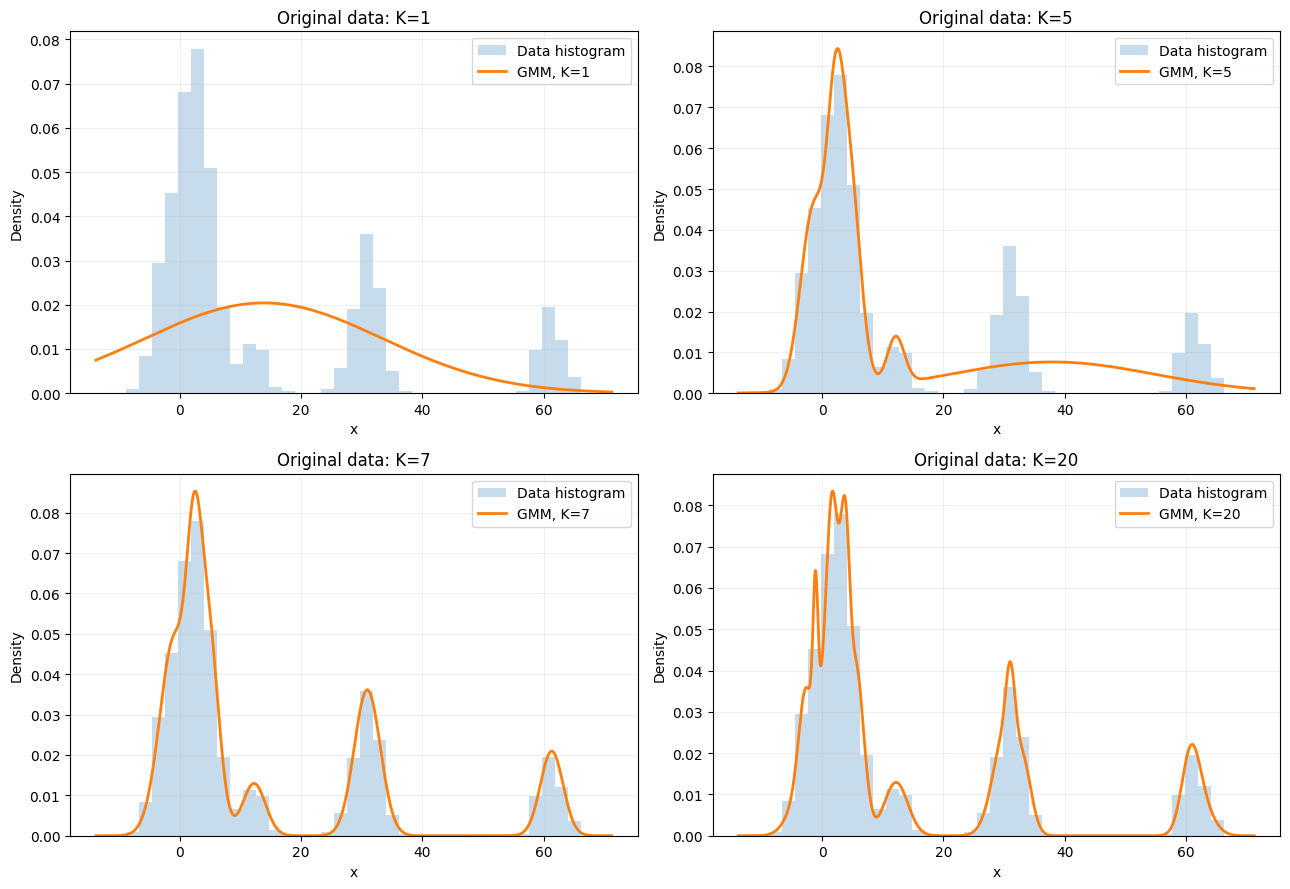

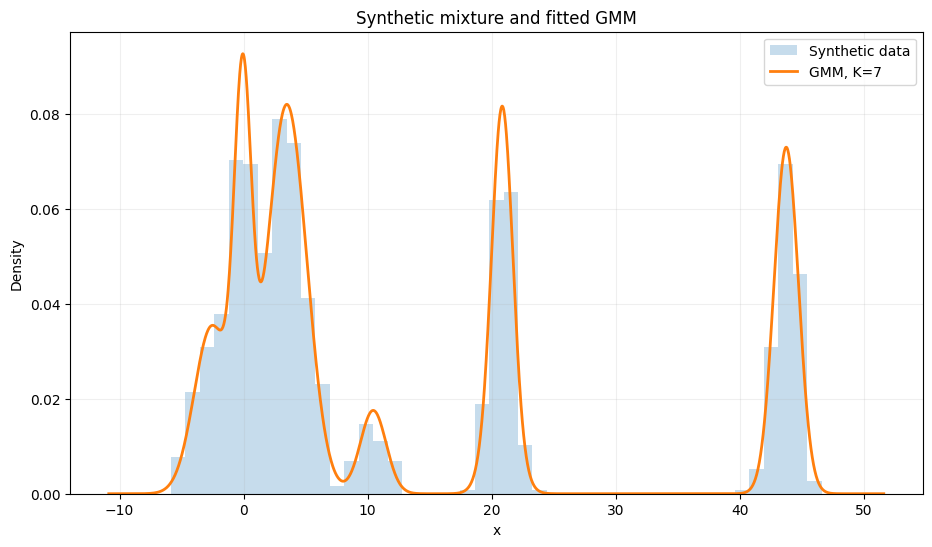

Estimated means: [-2.55646995 -0.06304624  3.48740634 10.4499055  20.7981662  20.86048693
 43.74474899]
Estimated standard deviations: [1.41891375 0.70074469 1.60120348 1.03932582 1.09835916 0.81441606
 0.98997016]
Estimated mixing coefficients: [0.1252547  0.13714716 0.32892498 0.04567316 0.05952208 0.12247792
 0.181     ]


In [ ]:
def gmm_1d_em(x, K, iterations=100):
    """
    1-D Gaussian Mixture Model trained using EM.
    The algorithm implements the responsibilities and M-step
    equations from the assignment.
    """
    x = np.asarray(x, dtype=float)
    N = len(x)

    # Initialization required by the assignment.
    mu = np.percentile(x, (np.arange(K) + 0.5) / K * 100)
    sigma = np.ones(K)
    pi = np.ones(K) / K

    for _ in range(iterations):
        # E-step:
        weighted_pdf = np.column_stack(
            [
                pi[k] * norm.pdf(x, loc=mu[k], scale=max(sigma[k], 1e-8))
                for k in range(K)
            ]
        )

        denominator = np.maximum(weighted_pdf.sum(axis=1, keepdims=True), 1e-300)
        gamma = weighted_pdf / denominator

        # M-step:
        Nk = gamma.sum(axis=0)

        mu = (gamma * x[:, None]).sum(axis=0) / np.maximum(Nk, 1e-300)

        variance = (gamma * (x[:, None] - mu[None, :]) ** 2).sum(axis=0) / np.maximum(
            Nk, 1e-300
        )

        sigma = np.sqrt(np.maximum(variance, 1e-8))
        pi = Nk / N

    return mu, sigma, pi


def mixture_pdf(x, mu, sigma, pi):
    y = np.zeros_like(x, dtype=float)
    for k in range(len(mu)):
        y += pi[k] * norm.pdf(x, loc=mu[k], scale=sigma[k])
    return y


# ============================================================
# PART 2 AND PART 3: Original data
# ============================================================

data = np.loadtxt("data.txt")
grid = np.linspace(data.min() - 5, data.max() + 5, 1500)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, K in zip(axes.ravel(), [1, 5, 7, 20]):
    mu, sigma, pi = gmm_1d_em(data, K, iterations=100)

    ax.hist(data, bins=35, density=True, alpha=0.25, label="Data histogram")
    ax.plot(grid, mixture_pdf(grid, mu, sigma, pi), linewidth=2, label=f"GMM, K={K}")

    ax.set_title(f"Original data: K={K}")
    ax.set_xlabel("x")
    ax.set_ylabel("Density")
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


# ============================================================
# PART 4: Synthetic mixture
# ============================================================

raw_weights = np.array([0.10, 0.20, 0.25, 0.10, 0.05, 0.20, 0.20])

means = np.array([-3.0, -0.05, 3.1, 5.0, 10.5, 20.9, 43.8])

stds = np.ones(7)

# The assignment's printed weights sum to 1.10.
# Normalize them to obtain valid sampling probabilities.
weights = raw_weights / raw_weights.sum()

rng = np.random.default_rng(42)

component = rng.choice(len(weights), size=1000, p=weights)

new_data = rng.normal(means[component], stds[component])

# Fit K=7 GMM.
mu, sigma, pi = gmm_1d_em(new_data, K=7, iterations=100)

grid = np.linspace(new_data.min() - 5, new_data.max() + 5, 1800)

plt.figure(figsize=(11, 6))

plt.hist(new_data, bins=45, density=True, alpha=0.25, label="Synthetic data")

plt.plot(grid, mixture_pdf(grid, mu, sigma, pi), linewidth=2, label="GMM, K=7")

plt.xlabel("x")
plt.ylabel("Density")
plt.title("Synthetic mixture and fitted GMM")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print("Estimated means:", mu)
print("Estimated standard deviations:", sigma)
print("Estimated mixing coefficients:", pi)